## Часть 5 задачи на отработку

### Задача 1: Сравнить два способа проверки вхождения в коллекцию

**Условие.** Даны два способа проверить, есть ли число в коллекции: `x in list` и `x in set`. Напишите бенчмарк, который для `n = 100, 1000, 10000` замеряет время 1000 проверок в `list` и в `set`. Постройте график с лог-шкалой по Y.

**Требования:**
- Используйте `timeit` (не ручной замер).
- Сделайте `repeat=5`, берите минимум.
- Лог-шкала по оси Y.
- Выведите, во сколько раз `set` быстрее на каждом `n`.

**Текстовые подсказки:**

1. **Подготовка данных.** Для каждого `n` создайте `data_list = list(range(n))` и `data_set = set(range(n))`. Ищите число, которого в коллекции **нет** (например, `-1`) — это худший случай для `list`: он пройдёт весь список до конца, и разница с `set` будет максимально наглядной.

2. **Как передать переменные в `timeit`.** Функция `timeit.repeat(stmt, globals=..., number=..., repeat=...)` принимает словарь `globals`, в котором лежат переменные, используемые в строке `stmt`. Например, `globals={"target": target, "data_list": data_list}`. Без этого `timeit` не увидит ваши данные.

3. **Нормировка на одну проверку.** `timeit` возвращает **суммарное** время за `number` выполнений. Чтобы получить время одной проверки, разделите результат на `number`. Затем умножьте на `1_000_000`, чтобы перевести секунды в микросекунды — так числа читаемее.

4. **Выбор лучшего замера.** `timeit.repeat` возвращает список из `repeat` значений. Берите `min(...)` — это защищает от случайных выбросов CPU.

5. **Лог-шкала.** После `ax.plot(...)` вызовите `ax.set_yscale("log")`. Для сетки, которая видна и на мелких делениях, используйте `ax.grid(True, which="both", alpha=0.2)`.

6. **Ожидаемый результат.** На лог-шкале линия `set` должна быть почти горизонтальной (O(1)), а линия `list` — расти с наклоном (O(n)). Если `list` не растёт — вы, скорее всего, ищете существующий элемент, и `list` находит его в начале.

7. **Вывод в консоль.** В цикле по `n` печатайте время обоих вариантов и отношение `t_list / t_set` — это и есть «во сколько раз быстрее».


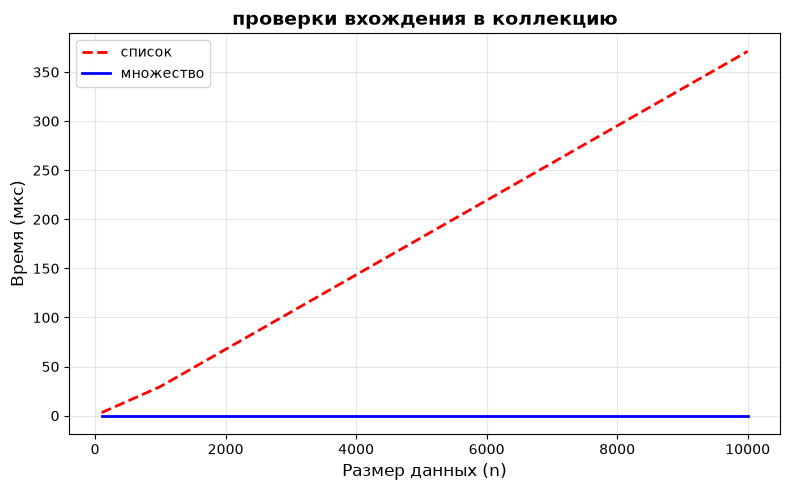

In [13]:
import timeit
import matplotlib.pyplot as plt

stmt1 = """
for v in data_list:
    if v == -1:
        break
"""        

stmt2 = """
-1 in data_set
"""

x1 = []
x2 = []

for n in (100, 1000, 10000):
    data_list = list(range(n))
    data_set = set(range(n))
    times1 = timeit.repeat(stmt1, globals={'data_list':data_list}, number=100, repeat=5)
    times2 = timeit.repeat(stmt2, globals={'data_set':data_set}, number=100, repeat=5)

    best1 = min(times1) / 100 * 1_000_000  # микросекунды
    best2 = min(times2) / 100 * 1_000_000  # микросекунды
    x1.append(best1)
    x2.append(best2)

# Создаём Figure с одной Axes
fig, ax = plt.subplots(figsize=(8, 5))

# Рисуем две линии с разными стилями
ax.plot((100, 1000, 10000), x1, label="список", color="red", linestyle="--", linewidth=2)
ax.plot((100, 1000, 10000), x2, label="множество", color="blue", linestyle="-", linewidth=2)

# Подписи осей и заголовок
ax.set_xlabel("Размер данных (n)", fontsize=12)
ax.set_ylabel("Время (мкс)", fontsize=12)
ax.set_title("проверки вхождения в коллекцию", fontsize=14, fontweight="bold")

# Легенда — какая линия что означает
ax.legend(fontsize=10, loc="upper left")

# Сетка для удобства чтения
ax.grid(True, alpha=0.3)

plt.tight_layout()  # автоматически подгоняет отступы
plt.show()


    





---

### Задача 2: Память для трёх способов создать список квадратов

**Условие.** Создайте список квадратов чисел `0..N-1` тремя способами: цикл с `append`, списочное включение (list comprehension) и `list(map(lambda ...))`. Для `N = 100_000` и `N = 1_000_000` измерьте время (`timeit`) и пиковую память (`tracemalloc`). Постройте два графика рядом: время и память.

**Требования:**
- Два `subplots` в одной строке.
- На графике памяти — столбцы (bar), на графике времени — линии с маркерами.
- Сделайте вывод, какой способ лучший и почему.

**Текстовые подсказки:**

1. **Три фрагмента кода.** Для `timeit` подготовьте три строки: `"out = []\nfor i in range(N):\n    out.append(i*i)"`, `"out = [i*i for i in range(N)]"` и `"out = list(map(lambda i: i*i, range(N)))"`. Обратите внимание на `\n` — многострочный код в `timeit` допустим, но отступы должны быть корректными.

2. **Замер времени.** Для каждого `N` и каждого фрагмента вызовите `timeit.repeat(stmt, globals={"N": N}, number=1, repeat=5)` и возьмите `min(...)`. `number=1` здесь достаточно: создание списка на миллион элементов — не микрооперация, повторять её 1000 раз внутри одного замера не нужно. Умножьте результат на `1000`, чтобы получить миллисекунды.

3. **Замер памяти.** `tracemalloc` работает так: `tracemalloc.start()` → выполнить код → `tracemalloc.get_traced_memory()` (возвращает кортеж `(current, peak)`) → `tracemalloc.stop()`. Вам нужен `peak` — пиковая память. Переведите байты в МБ делением на `1024 * 1024`.

4. **Как выполнить тот же код для замера памяти.** `timeit` выполняет строку, а `tracemalloc` — нет. Используйте `exec(stmt, {"N": N})` — это выполнит ту же строку в отдельном пространстве имён. Важно: `exec` не возвращает значение, но нам оно и не нужно — нам нужен факт создания списка.

5. **Графики рядом.** `fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))`. На `ax1` — линии времени (`ax1.plot(...)` с маркерами `"o-"`), на `ax2` — столбцы памяти. Для столбцов по трём алгоритмам на каждом `N` используйте группировку: `x = range(len(N_values))`, `width = 0.25`, и сдвигайте столбцы на `(i - 1) * width`.

6. **Подписи на оси X для столбцов.** После `ax2.bar(...)` вызовите `ax2.set_xticks(list(x))` и `ax2.set_xticklabels([f"N={N}" for N in N_values])`. Без этого на оси X будут числа 0, 1, а не размеры.

7. **Ожидаемый результат по памяти.** Все три способа дадут **примерно одинаковую** пиковую память — ведь результат один и тот же список на миллион `int`. Промежуточные объекты (`append`-вызовы, lambda-вызовы) краткоживущие и почти не влияют на пик. Это важный вывод: память определяется **результатом**, а не способом его получения.

8. **Ожидаемый результат по времени.** List comprehension обычно быстрее всех: цикл выполняется на уровне C без вызовов `append`. `map + lambda` проигрывает из-за накладных расходов на вызов lambda для каждого элемента. Ручной цикл с `append` — где-то посередине или медленнее всех.

9. **Формулировка вывода.** В конце скрипта напишите `print(...)` с тремя пунктами: (а) по памяти все способы равны, потому что результат одинаковый; (б) по времени list comprehension быстрее из-за отсутствия вызовов `append`; (в) `map + lambda` медленнее из-за накладных расходов на lambda.


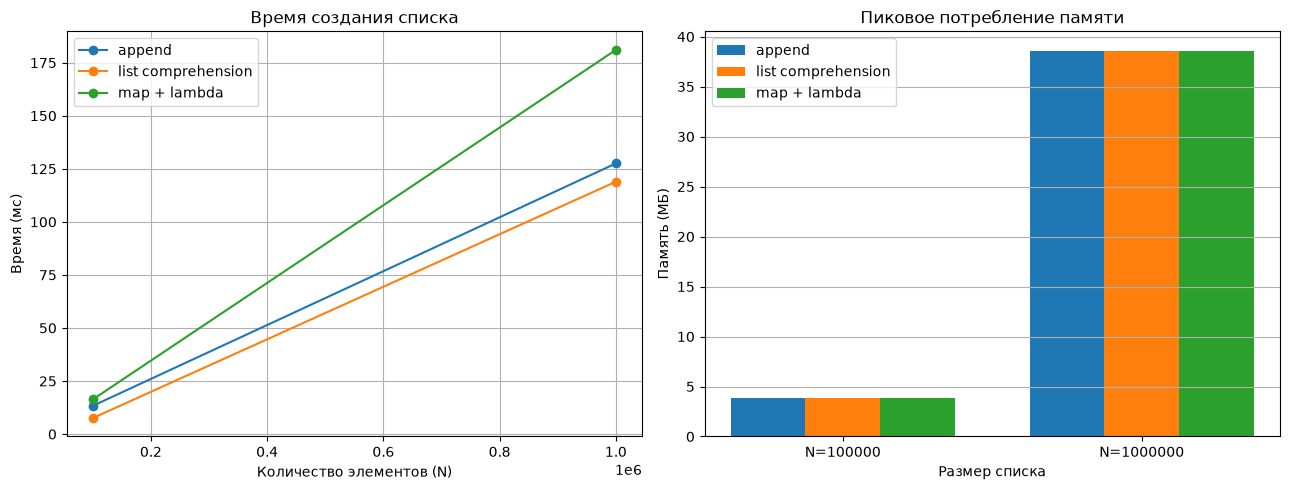

Вывод:
1. По памяти все три способа примерно равны, так как создают одинаковый список.
2. List comprehension обычно быстрее благодаря оптимизации выполнения в Python.
3. Map + lambda может работать медленнее из-за накладных расходов на вызов lambda для каждого элемента.


In [14]:
import tracemalloc

stmt1 = "out = []\nfor i in range(N):\n    out.append(i*i)"
stmt2 = "out = [i*i for i in range(N)]"
stmt3 = "out = list(map(lambda i: i*i, range(N)))"

N_values = [100_000, 1_000_000]

# [размер N][способ создания списка]
x = [[[], [], []], [[], [], []]]
x2 = [[[], [], []], [[], [], []]]

for i, N in enumerate(N_values):
    for j, stmt in enumerate((stmt1, stmt2, stmt3)):
        # Замер времени
        times = timeit.repeat(stmt, globals={"N": N}, number=1, repeat=5)
        best = min(times) * 1000  # миллисекунды
        x[i][j].append(best)

        # Замер памяти
        tracemalloc.start()
        exec(stmt, {"N": N})
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()

        x2[i][j].append(peak / (1024 * 1024))  # МБ

# Построение графиков
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

names = ["append", "list comprehension", "map + lambda"]

# График времени
for i, name in enumerate(names):
    ax1.plot(
        N_values,
        [x[j][i][0] for j in range(2)],
        "o-",
        label=name
    )

ax1.set_title("Время создания списка")
ax1.set_xlabel("Количество элементов (N)")
ax1.set_ylabel("Время (мс)")
ax1.legend()
ax1.grid(True)

# График памяти
x_pos = range(len(N_values))
width = 0.25

for i, name in enumerate(names):
    ax2.bar(
        [p + (i - 1) * width for p in x_pos],
        [x2[j][i][0] for j in range(2)],
        width,
        label=name
    )

ax2.set_title("Пиковое потребление памяти")
ax2.set_xlabel("Размер списка")
ax2.set_ylabel("Память (МБ)")
ax2.set_xticks(list(x_pos))
ax2.set_xticklabels([f"N={N}" for N in N_values])
ax2.legend()
ax2.grid(axis="y")

plt.tight_layout()
plt.show()

# Вывод
print("Вывод:")
print("1. По памяти все три способа примерно равны, так как создают одинаковый список.")
print("2. List comprehension обычно быстрее благодаря оптимизации выполнения в Python.")
print("3. Map + lambda может работать медленнее из-за накладных расходов на вызов lambda для каждого элемента.")